In [48]:
from collections import Counter
from pathlib import Path
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.utils.class_weight import compute_class_weight

# 1- Découverte et préparation des données

#### Explorer la structure du dataset et les classes

In [11]:
DATA_DIR = Path('../data/row')

classes = ["glioma", "meningioma", "notumor", "pituitary"]

for class_name in classes:
    class_dir = DATA_DIR / class_name

    if class_dir.exists():
        images = list(class_dir.iterdir())
        print(f'{class_name} : {len(images)} fichiers')
    else:
        print(f'{class_name}: dosser introuvable')

glioma : 1621 fichiers
meningioma : 1645 fichiers
notumor : 2000 fichiers
pituitary : 1757 fichiers


#### Valider les formats

In [30]:
extensions_valides = {".jpeg", ".jpg", ".bmp", ".png"}

for class_name in classes:
    class_dir = DATA_DIR / class_name
    if not class_dir.exists():
        print(f'{class_name}: introuvable')
        continue

    images = []
    for file_path in class_dir.iterdir():
        if file_path.suffix.lower() not in extensions_valides or not file_path.is_file():
            continue
        try:
            with Image.open(file_path) as image:
                image.verify()
            images.append(file_path)
        except (OSError, ValueError, SyntaxError):
            print(f"Image illisible ou corrompue : {file_path}")

    extensions = Counter(img.suffix.lower() for img in images)

    print(f"\nClasse: {class_name}")
    print(f"Nombre total de fichiers: {len(images)}")
    print(f"Extensions: {dict(extensions)}")


Classe: glioma
Nombre total de fichiers: 1621
Extensions: {'.jpg': 1621}

Classe: meningioma
Nombre total de fichiers: 1645
Extensions: {'.jpg': 1645}

Classe: notumor
Nombre total de fichiers: 2000
Extensions: {'.jpg': 2000}

Classe: pituitary
Nombre total de fichiers: 1757
Extensions: {'.jpg': 1757}


#### Redimensionner et normaliser les images et le chargeur de données réutilisable

In [39]:
IMAGE_SIZE = (224, 224)

images = []
labels = []

for class_path in DATA_DIR.iterdir():
    if not class_path.is_dir():
        continue

    # label de image
    label = class_path.name

    for image_path in class_path.iterdir():
        try:
            # load image
            image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
            if image is None:
                continue
            # Resize
            image_resized = cv2.resize(image, IMAGE_SIZE)

            # Normalisation des pixels entre 0 et 1
            image_normalized = image_resized.astype(np.float32) / 255

            # ajouter image et label dans lists
            images.append(image_normalized)
            labels.append(label)
        except Exception as e:
             print(f"Erreur avec {image_path}: {e}")

# mélanger les données
images, labels = shuffle(
    images,
    labels,
    random_state=26
)

# les listes en tableaux NumPy
X = np.array(images, dtype=np.float32)
Y = np.array(labels)

print("X shape :", X.shape)
print("y shape :", Y.shape)
print("Labels :", np.unique(Y))

X shape : (7023, 224, 224)
y shape : (7023,)
Labels : ['glioma' 'meningioma' 'notumor' 'pituitary']


##### exemple avant et après transformation

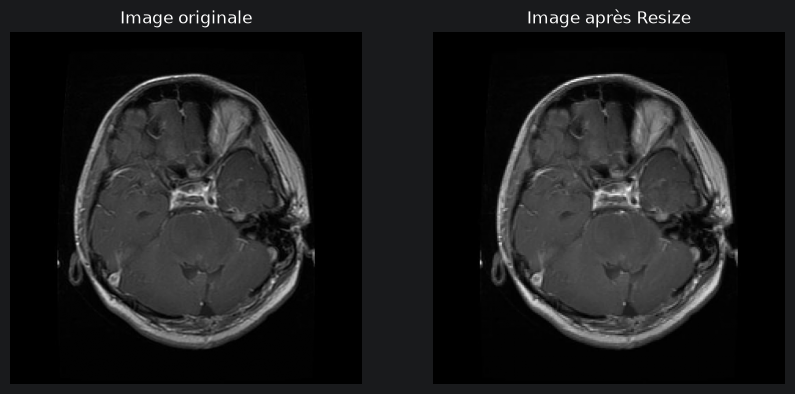

In [35]:
image_path = DATA_DIR / 'glioma/Te-gl_0010.jpg'
image_origin = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

image_resized = cv2.resize(image_origin, IMAGE_SIZE)

image_normalized = image_resized.astype(np.float32) / 255

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_origin, cmap="gray")
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_normalized, cmap="gray")
plt.title("Image après Resize")
plt.axis("off")

plt.show()

#### Vérifier la distribution des labels

glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


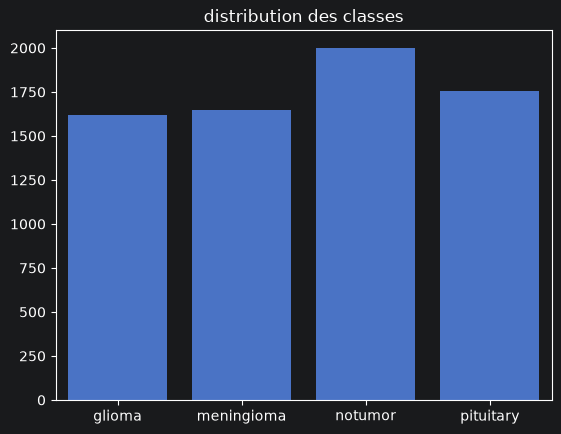

In [41]:
# distribution des classes
labels_unique, labels_counts = np.unique(labels, return_counts=True)

for label, count in zip(labels_unique, labels_counts):
    print(f"{label} : {count} images")

plt.figure()
sns.barplot(
    x=labels_unique,
    y=labels_counts
)
plt.title('distribution des classes')
plt.show()

#### Encoder les labels et traiter le déséquilibre

In [47]:
# LabelEncoder
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(Y)

print(y_encoded)
print(encoder.classes_)

# One-Hot Encoding avec to_categorical
y_categorical = to_categorical(y_encoded)
print(y_categorical)

# Class Imbalance : solution avec class_weight
classes = np.unique(y_encoded)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_encoded
)

class_weight = dict(zip(classes, weights))

print(class_weight)

[3 3 2 ... 0 0 3]
['glioma' 'meningioma' 'notumor' 'pituitary']
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 ...
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]]
{np.int64(0): np.float64(1.0831276989512646), np.int64(1): np.float64(1.067325227963526), np.int64(2): np.float64(0.877875), np.int64(3): np.float64(0.9992885600455321)}


#### Séparer les données en Train et Test

In [50]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=26
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", Y_train.shape)
print("y_test :", Y_test.shape)

X_train : (5618, 224, 224)
X_test : (1405, 224, 224)
y_train : (5618,)
y_test : (1405,)
